In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import keras
import tensorflow as tf
from tensorflow.keras.datasets import mnist

In [70]:
mnist.load_data()

((array([[[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         ...,
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0

* The first array contains the info of the pixels (x-train)
* The second array contains labels what is image holding and its y-train.
* The 3rd array contains pixcel x-test
* The 4th array y-test

In [71]:
(x_train,y_train),(x_test,y_test) = mnist.load_data()
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(60000, 28, 28)
(10000, 28, 28)
(60000,)
(10000,)


* Dataset contains 60,000 images and the size of the pixel is 28*28=784
* The size of the y_train label is same
* The x_test contains 10000 images and y_test contains 10000 labels

In [72]:
x_train.ndim

3

In [73]:
x_train = x_train.reshape(60000,784)
x_test = x_test.reshape(10000,784)

In [74]:
x_train.shape,x_test.shape

((60000, 784), (10000, 784))

In [75]:
x_train.ndim

2

* The ANN model take input data in 1D form but currently our data is in 3D form So for that we need convert our 3D to 2D form.
* In total we have 784 pixel and 60000 so if we convert into the 2D the row size will be 60000 and column size 784. So it pass the data rowise so the data passing will be in 1D.

In [76]:
x_train = x_train/255
x_test = x_test/255

* The pixel's values are ranging btw 0 to 255 so model to make learn the easily we are deviding by 255 so the data become noramlized (0 to 1)

In [77]:
np.unique(y_train)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

In [78]:
np.unique(y_test)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

* So our data set having the different unique class so our probelm is classification (Multiclass)

In [79]:
y_train[0]

np.uint8(5)

* Here the first data of the y_train having single digit. Means there will be single neuron created in the output layer.
* But for multiclass if we need to use the function(parameter) SoftMax we need same number of neuron. So to do that do the below method. Which will create the multi neruons in output layer to use the Softmax.
* But note that i will not effect the Original digit.
* And it for every data it create 10 neurons in output layer.

In [80]:
y_train = tf.keras.utils.to_categorical(y_train)
y_test = tf.keras.utils.to_categorical(y_test)

In [81]:
y_train[0]

array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.])

### Simple Percepton (Single layerd Network)

In [82]:
epochs = 10
batch_size = 1000
n_classes = 10 # No. of Neuron's need in Ouputlayer

In [83]:
### Model Building
perc = tf.keras.models.Sequential()
perc.add(tf.keras.layers.Dense(units=n_classes,activation='softmax',input_shape=[784]))

* The ANN is a Sequnetial Model so we have to give model as Sequantial.
* Units we have to give means how many neurons we need in the outputlayer
* Activation is the function we wants to use in the Hidden layer or Output layer we have to mention that the softmax is funciton used in the output function. So input size we have to give how many number of columns or features we have.

In [84]:
### Model Compile
perc.compile(optimizer=tf.keras.optimizers.Adam(),
              loss= tf.keras.losses.categorical_crossentropy,metrics=['accuracy'])

* In model compileation part we wants to mention which optimizer we wants to use and mention the loss wt we wants to calculate its multiclass problem so we use categorical_cross_entropy.

In [85]:
#### Model Training and Validation
perc.fit(x_train,y_train,epochs=10, batch_size=batch_size, validation_data=(x_test,y_test))

Epoch 1/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6532 - loss: 1.4062 - val_accuracy: 0.8226 - val_loss: 0.8669
Epoch 2/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8368 - loss: 0.7349 - val_accuracy: 0.8664 - val_loss: 0.5963
Epoch 3/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8655 - loss: 0.5635 - val_accuracy: 0.8825 - val_loss: 0.4923
Epoch 4/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8797 - loss: 0.4847 - val_accuracy: 0.8925 - val_loss: 0.4367
Epoch 5/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8884 - loss: 0.4379 - val_accuracy: 0.8984 - val_loss: 0.4010
Epoch 6/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8947 - loss: 0.4067 - val_accuracy: 0.9029 - val_loss: 0.3771
Epoch 7/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8993 - loss: 0.3845 - val_accuracy: 0.9065 - val_loss: 0.3585
Epoch 8/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9027 - loss: 0.3672 - val_accuracy: 0.9085 - val_l

### Multilayered Percepton

In [86]:
Ann = tf.keras.models.Sequential()
### First Hidden layer, Input layer
Ann.add(tf.keras.layers.Dense(units=540,activation='relu',input_shape=(784,)))

### Second Hidden layer, Input layer
Ann.add(tf.keras.layers.Dense(units=370,activation='relu'))

### Output Layer
Ann.add(tf.keras.layers.Dense(units=10,activation='softmax'))
Ann.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 540)            │       423,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 370)            │       200,170 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         3,710 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 627,780 (2.39 MB)

 Trainable params: 627,780 (2.39 MB)

 Non-trainable params: 0 (0.00 B)

* So in the first hidden layer We are using 540 Neurons Based on the calculation done by resarechers That is total_no.feature*2/3+10 i.e is 784*2/3+10=532 we are taken 540.
* So in 2nd Hidden layer based Neurons in the 1st hidden layer the Neuron for 2nd hidden layer are calculated i.e 540*2/3+10=370.

In [87]:
### Model Compile
Ann.compile(optimizer=tf.keras.optimizers.Adam(),
            loss= tf.keras.losses.categorical_crossentropy,metrics=['accuracy'])

In [88]:
### Model Training and Validation
history = Ann.fit(x_train,y_train,epochs=epochs,batch_size=batch_size, validation_data=(x_test,y_test))

Epoch 1/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step - accuracy: 0.8719 - loss: 0.4658 - val_accuracy: 0.9428 - val_loss: 0.1988
Epoch 2/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 66ms/step - accuracy: 0.9546 - loss: 0.1590 - val_accuracy: 0.9634 - val_loss: 0.1247
Epoch 3/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 93ms/step - accuracy: 0.9692 - loss: 0.1066 - val_accuracy: 0.9696 - val_loss: 0.0981
Epoch 4/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - accuracy: 0.9778 - loss: 0.0772 - val_accuracy: 0.9745 - val_loss: 0.0818
Epoch 5/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - accuracy: 0.9838 - loss: 0.0559 - val_accuracy: 0.9768 - val_loss: 0.0744
Epoch 6/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step - accuracy: 0.9881 - loss: 0.0439 - val_accuracy: 0.9764 - val_loss: 0.0704
Epoch 7/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - accuracy: 0.9901 - loss: 0.0346 - val_accuracy: 0.9788 - val_loss: 0.0645
Epoch 8/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 93ms/step - accuracy: 0.9924 - loss: 0.0273 - val_accuracy: 0.9789 - v

In [89]:
loss,val_acc = Ann.evaluate(x_test,y_test)
print('Loss',loss,  'Val_Acc',val_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9819 - loss: 0.0653
Loss 0.06534824520349503 Val_Acc 0.9818999767303467


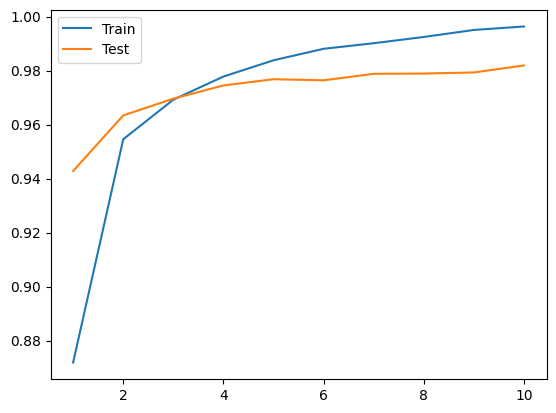

In [90]:
plt.plot(range(1,11),history.history['accuracy'],label='Train')
plt.plot(range(1,11),history.history['val_accuracy'],label='Test')
plt.legend()

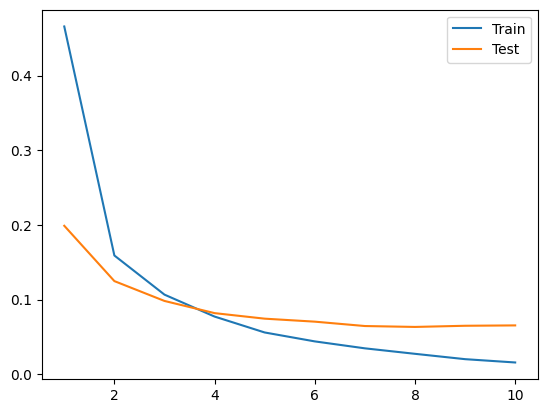

In [91]:
plt.plot(range(1,11),history.history['loss'],label='Train')
plt.plot(range(1,11),history.history['val_loss'],label='Test')
plt.legend()

* The above graphs shows with each epochs how the accuracy is changing we can visulaizes weather accuracy is increasing or not.
* In second graph we can visualy see with each epocahs the error is decreassing.

In [92]:
x_test[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

 * These are the pixel values of the first image in the dataset.

In [93]:
Ann.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


array([[2.5598190e-08, 1.7400602e-08, 1.1046782e-06, ..., 9.9998778e-01,
        1.1954441e-07, 6.3886330e-07],
       [6.5322853e-10, 9.8059814e-08, 9.9999946e-01, ..., 1.7237781e-12,
        8.5561602e-08, 1.5675895e-14],
       [1.2153258e-06, 9.9876320e-01, 5.9840495e-05, ..., 5.5255130e-04,
        3.9867059e-04, 2.4207056e-06],
       ...,
       [4.0015612e-14, 1.6444081e-12, 2.5336549e-14, ..., 9.8545598e-09,
        3.0309502e-09, 1.7622362e-07],
       [7.5527751e-11, 3.5611517e-11, 1.7447264e-12, ..., 2.8985939e-11,
        2.3788732e-06, 9.5091730e-13],
       [1.0051081e-10, 1.3414105e-12, 1.2297255e-11, ..., 5.8458483e-15,
        6.1215937e-12, 6.0480531e-14]], shape=(10000, 10), dtype=float32)

* This is the probability value of the neurons. in Output layer we have seted 10 neurons.
* For that we are getting the 10 probability values. in which position we are having the highest probability value that class the neuron belongs to.

In [94]:
y_pred = Ann.predict(x_test)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [95]:
y_test[0]

array([0., 0., 0., 0., 0., 0., 0., 1., 0., 0.])

* So our first row belongs to the 7th class

In [96]:
np.argmax(y_pred[0])

np.int64(7)

* So for the first row the original class is also 7 and predicted or class also 7

In [97]:
act = []
for i in range(len(y_test)):
  act.append(np.argmax(y_test[i]))
print(act)

[np.int64(7), np.int64(2), np.int64(1), np.int64(0), np.int64(4), np.int64(1), np.int64(4), np.int64(9), np.int64(5), np.int64(9), np.int64(0), np.int64(6), np.int64(9), np.int64(0), np.int64(1), np.int64(5), np.int64(9), np.int64(7), np.int64(3), np.int64(4), np.int64(9), np.int64(6), np.int64(6), np.int64(5), np.int64(4), np.int64(0), np.int64(7), np.int64(4), np.int64(0), np.int64(1), np.int64(3), np.int64(1), np.int64(3), np.int64(4), np.int64(7), np.int64(2), np.int64(7), np.int64(1), np.int64(2), np.int64(1), np.int64(1), np.int64(7), np.int64(4), np.int64(2), np.int64(3), np.int64(5), np.int64(1), np.int64(2), np.int64(4), np.int64(4), np.int64(6), np.int64(3), np.int64(5), np.int64(5), np.int64(6), np.int64(0), np.int64(4), np.int64(1), np.int64(9), np.int64(5), np.int64(7), np.int64(8), np.int64(9), np.int64(3), np.int64(7), np.int64(4), np.int64(6), np.int64(4), np.int64(3), np.int64(0), np.int64(7), np.int64(0), np.int64(2), np.int64(9), np.int64(1), np.int64(7), np.int64(3)

In [98]:
pred=[]
for i in range(len(y_pred)):
  pred.append(np.argmax(y_pred[i]))
print(pred)

[np.int64(7), np.int64(2), np.int64(1), np.int64(0), np.int64(4), np.int64(1), np.int64(4), np.int64(9), np.int64(6), np.int64(9), np.int64(0), np.int64(6), np.int64(9), np.int64(0), np.int64(1), np.int64(5), np.int64(9), np.int64(7), np.int64(3), np.int64(4), np.int64(9), np.int64(6), np.int64(6), np.int64(5), np.int64(4), np.int64(0), np.int64(7), np.int64(4), np.int64(0), np.int64(1), np.int64(3), np.int64(1), np.int64(3), np.int64(4), np.int64(7), np.int64(2), np.int64(7), np.int64(1), np.int64(2), np.int64(1), np.int64(1), np.int64(7), np.int64(4), np.int64(2), np.int64(3), np.int64(5), np.int64(1), np.int64(2), np.int64(4), np.int64(4), np.int64(6), np.int64(3), np.int64(5), np.int64(5), np.int64(6), np.int64(0), np.int64(4), np.int64(1), np.int64(9), np.int64(5), np.int64(7), np.int64(8), np.int64(9), np.int64(3), np.int64(7), np.int64(4), np.int64(6), np.int64(4), np.int64(3), np.int64(0), np.int64(7), np.int64(0), np.int64(2), np.int64(9), np.int64(1), np.int64(7), np.int64(3)

* Here Through looping we are saving each act values to belonging class.
* With the same method with the help of argmax we are saving the output which class is it belonging.

In [99]:
from sklearn.metrics import accuracy_score,classification_report

In [100]:
accuracy_score(act,pred)

0.9819

In [101]:
classification_report(act,pred)

'              precision    recall  f1-score   support\n\n           0       0.99      0.99      0.99       980\n           1       1.00      0.99      0.99      1135\n           2       0.98      0.98      0.98      1032\n           3       0.98      0.98      0.98      1010\n           4       0.97      0.99      0.98       982\n           5       0.99      0.98      0.98       892\n           6       0.97      0.99      0.98       958\n           7       0.98      0.98      0.98      1028\n           8       0.99      0.96      0.97       974\n           9       0.98      0.97      0.98      1009\n\n    accuracy                           0.98     10000\n   macro avg       0.98      0.98      0.98     10000\nweighted avg       0.98      0.98      0.98     10000\n'